# Q11 - Manhattan-Distance Iterative Deepening for Mobile Phone Features

Same code as `q11_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q11 - Manhattan-distance iterative deepening search to expand the conceptual space
of mobile phone features.

Each phone design is a point in a feature space (levels 0-6). Iteration d explores every
design within Manhattan distance d of today's phone, so each iteration grows the search
space by one ring. When the rings stop paying off, we expand the conceptual space itself
by adding a brand-new dimension (an IoT health sensor).
"""
import os

import matplotlib.pyplot as plt
import numpy as np

os.makedirs("images", exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

FEATURES = ["camera", "battery", "screen", "ai_chip", "foldable", "health_sensor"]
MAX_LEVEL = [6, 6, 6, 6, 2, 3]
A = [9, 8, 6, 10, 7, 9]               # value gained per level
B = [0.9, 0.8, 0.9, 1.0, 2.2, 1.6]    # diminishing returns (cost, weight, heat)
U_MAX = sum(a * a / (4 * b) for a, b in zip(A, B))
MARKET = [(3, 3, 3, 2, 0), (5, 5, 3, 5, 0), (2, 6, 2, 1, 0), (4, 3, 5, 3, 2), (1, 2, 2, 0, 0)]
START = (3, 3, 3, 2, 0)               # today's phone
MIN_GAIN = 1.0                        # a ring must beat the best by 1 point


def manhattan(p: tuple, q: tuple) -> int:
    return sum(abs(a - b) for a, b in zip(p, q))


def utility(s: tuple) -> float:
    return 100 * sum(a * x - b * x * x for a, b, x in zip(A, B, s)) / U_MAX


def novelty(s: tuple) -> float:
    """Distance to the closest phone already on the market (0 = copy, 100 = very new)."""
    pad = len(s) - 5
    return 100 * min(1.0, min(manhattan(s, m + (0,) * pad) for m in MARKET) / 4)


def score(s: tuple) -> float:
    return 0.75 * utility(s) + 0.25 * novelty(s)   # useful AND new = creative


def neighbours(s: tuple, dims: list):
    for i in dims:
        for step in (-1, 1):
            if 0 <= s[i] + step <= MAX_LEVEL[i]:
                yield s[:i] + (s[i] + step,) + s[i + 1:]


def depth_limited(start: tuple, limit: int, dims: list) -> set:
    """DFS that never leaves the Manhattan ball of radius `limit` around the start."""
    stack, seen = [start], {start}
    while stack:
        s = stack.pop()
        for n in neighbours(s, dims):
            if n not in seen and manhattan(n, start) <= limit:
                seen.add(n)
                stack.append(n)
    return seen


def manhattan_ids(start: tuple, dims: list, max_d: int = 14, patience: int = 2):
    """Iteration d re-explores the whole ball of radius d and scores its outer ring."""
    best, stale, history = start, 0, []
    for d in range(max_d + 1):
        ball = depth_limited(start, d, dims)
        ring = [s for s in ball if manhattan(s, start) == d]
        if not ring:                   # the whole space is already covered
            break
        top = max(ring, key=score)
        history.append((d, len(ball), len(ring), top, score(top)))
        if score(top) >= score(best) + MIN_GAIN:
            best, stale = top, 0
        else:
            stale += 1
        if stale >= patience:          # two rings in a row added nothing better
            break
    return best, history


def show(title: str, history: list) -> None:
    print(title)
    print("   d | ball size | ring size | best design on ring    | score")
    for d, ball, ring, top, sc in history:
        print(f"  {d:>2} | {ball:>9} | {ring:>9} | {str(top):<22} | {sc:5.1f}")


print("Q11  Manhattan-distance IDS over phone designs")
print(f"start phone {START} (camera,battery,screen,ai,fold): score {score(START):.1f}")
best5, hist5 = manhattan_ids(START, dims=[0, 1, 2, 3, 4])
show("Stage 1: 5 known features", hist5)
print(f"plateau -> best {best5}, score {score(best5):.1f}; add new dimension 'health_sensor'")

start6 = START + (0,)
best6, hist6 = manhattan_ids(start6, dims=[0, 1, 2, 3, 4, 5])
print(f"Stage 2: 6 features -> best {best6}, score {score(best6):.1f} "
      f"(+{score(best6) - score(best5):.1f}) after {len(hist6)} iterations")

bestg, histg = manhattan_ids(START, dims=[0, 2, 3])
full_cost = sum(h[1] for h in hist5)
guided_cost = sum(h[1] for h in histg)
print(f"Guided path (red arrow: camera+screen+AI only): best {bestg}, score {score(bestg):.1f}")
print(f"states generated: full rings {full_cost}, guided {guided_cost} "
      f"({100 * guided_cost / full_cost:.0f}% of the work)")

# ---------------- chart 1: Diagram-4 style view (camera x AI slice) ----------------
fig, ax = plt.subplots(figsize=(6.0, 6.4))
grid = np.zeros((7, 7))
for c in range(7):
    for a in range(7):
        grid[a, c] = score((c, START[1], START[2], a, START[4]))
ax.imshow(grid, origin="lower", cmap="YlOrBr", alpha=0.55, extent=(-0.5, 6.5, -0.5, 6.5))
for c in range(7):
    for a in range(7):
        ax.text(c, a, f"{grid[a, c]:.0f}", ha="center", va="center", fontsize=7.5, color="#374151")
cx, cy = START[0], START[3]
for d in range(1, 5):
    ax.plot([cx - d, cx, cx + d, cx, cx - d], [cy, cy + d, cy, cy - d, cy], color="#3a6ea5",
            lw=1.3, ls="--")
    if cy + d <= 6:
        ax.text(cx + 0.12, cy + d - 0.32, f"d={d}", color="#1d4ed8", fontsize=8.5, fontweight="bold")
ax.scatter([cx], [cy], s=260, color="#2a9d8f", zorder=4, label="today's phone (start)")
ax.annotate("", xy=(best5[0], best5[3]), xytext=(cx, cy),
            arrowprops=dict(arrowstyle="-|>", color="#d62828", lw=2.4, mutation_scale=18))
ax.scatter([best5[0]], [best5[3]], s=200, marker="*", color="#d62828", zorder=5,
           label="best design found (projection)")
ax.set_xlabel("camera level")
ax.set_ylabel("AI-chip level")
ax.set_xticks(range(7))
ax.set_yticks(range(7))
ax.set_xlim(-0.5, 6.5)
ax.set_ylim(-0.5, 6.5)
ax.grid(False)
ax.set_title("Rings of Manhattan distance around the start\n(cell = creative score)", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig("images/q11_chart1_rings.png")
plt.close(fig)

# ---------------- chart 2: work per iteration and best score per ring ----------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9))
w = 0.27
for k, (hist, lab, col) in enumerate([(hist5, "5 features (full rings)", "#3a6ea5"),
                                      (hist6, "6 features (+ sensor)", "#e76f51"),
                                      (histg, "guided (camera+screen+AI)", "#2a9d8f")]):
    a1.bar(np.array([h[0] for h in hist]) + (k - 1) * w, [h[1] for h in hist], w, label=lab,
           color=col)
a1.set_yscale("log")
a1.set_xlabel("iteration d (Manhattan radius)")
a1.set_ylabel("states explored in iteration (log)")
a1.set_title("Each iteration expands the search space")
a1.legend(fontsize=8)
a2.plot([h[0] for h in hist5], [h[4] for h in hist5], "o-", color="#3a6ea5", label="5 features")
a2.plot([h[0] for h in hist6], [h[4] for h in hist6], "s-", color="#e76f51",
        label="6 features (new dimension)")
a2.plot([h[0] for h in histg], [h[4] for h in histg], "^--", color="#2a9d8f", label="guided")
a2.set_xlabel("iteration d (Manhattan radius)")
a2.set_ylabel("best creative score on ring d")
a2.set_title("Best design per ring")
a2.legend(fontsize=8)
fig.tight_layout()
fig.savefig("images/q11_chart2_iterations.png")
plt.close(fig)
print("charts saved to images/")


Q11  Manhattan-distance IDS over phone designs
start phone (3, 3, 3, 2, 0) (camera,battery,screen,ai,fold): score 48.3


Stage 1: 5 known features
   d | ball size | ring size | best design on ring    | score
   0 |         1 |         1 | (3, 3, 3, 2, 0)        |  48.3
   1 |        10 |         9 | (3, 3, 3, 3, 0)        |  58.4
   2 |        51 |        41 | (3, 3, 3, 3, 1)        |  68.4
   3 |       178 |       127 | (3, 3, 3, 4, 1)        |  77.0
   4 |       476 |       298 | (4, 3, 3, 4, 1)        |  85.4
   5 |      1034 |       558 | (4, 4, 3, 4, 1)        |  87.3
   6 |      1893 |       859 | (4, 4, 3, 4, 2)        |  87.6
   7 |      2999 |      1106 | (4, 4, 3, 5, 2)        |  88.4
   8 |      4201 |      1202 | (4, 4, 4, 5, 2)        |  88.2
   9 |      5307 |      1106 | (5, 4, 4, 5, 2)        |  88.9
plateau -> best (4, 4, 3, 5, 2), score 88.4; add new dimension 'health_sensor'


Stage 2: 6 features -> best (5, 5, 3, 5, 1, 3), score 99.3 (+10.9) after 14 iterations
Guided path (red arrow: camera+screen+AI only): best (4, 3, 4, 4, 0), score 81.4
states generated: full rings 16150, guided 652 (4% of the work)


charts saved to images/


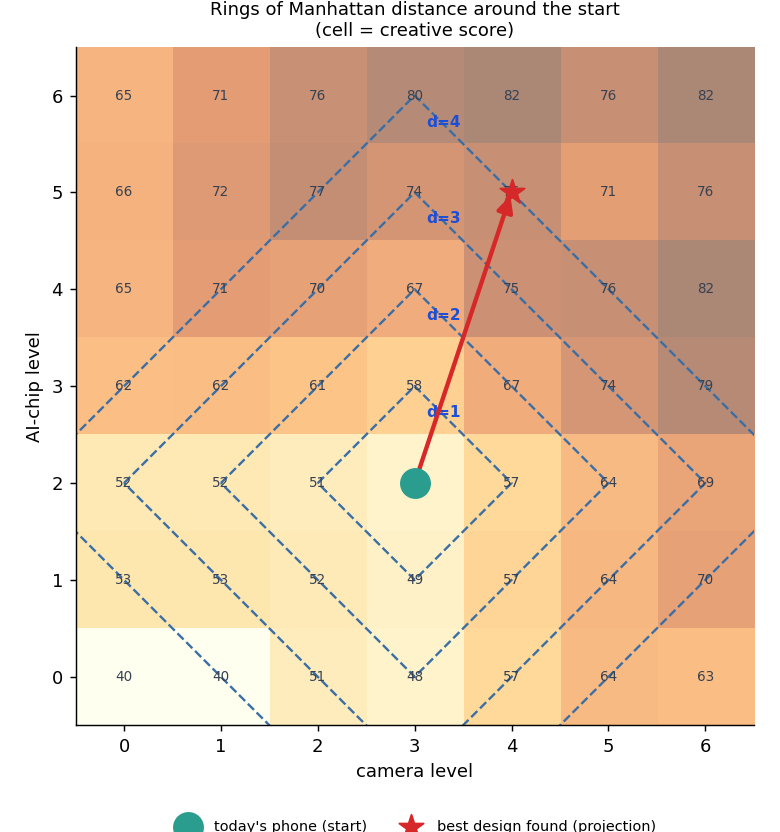

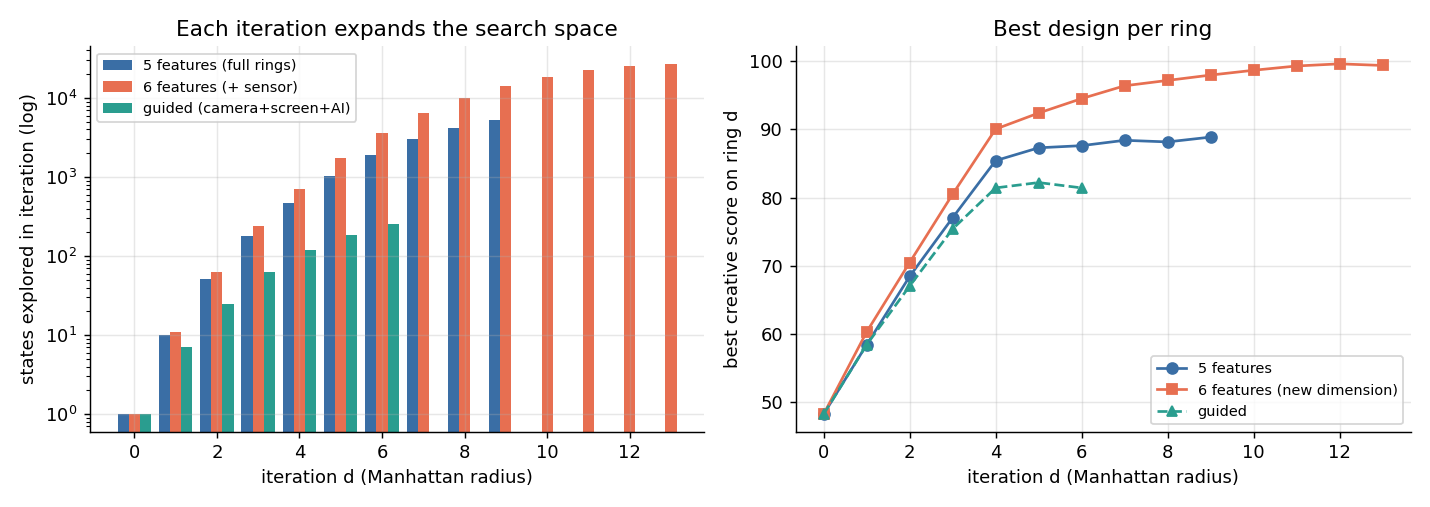

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q11_chart*.png')):
    display(Image(p))